# Homework 4

#### Data Preparation

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [43]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [44]:
#print(df.isnull().sum())
print(df.dtypes)
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object


In [45]:
df.converted.value_counts(normalize=True)

converted
1    0.5766
0    0.4234
Name: proportion, dtype: float64

In [46]:
for c in categorical:
    df[c] = df[c].fillna('NA')

for n in numerical:
    df[n] = df[n].fillna(0)

In [47]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

Split dataset

In [48]:
from sklearn.model_selection import train_test_split

In [49]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

### Question 1: ROC AUC feature importance

In [81]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

In [51]:
for n in numerical:
    col = df_train[n]
    auc = roc_auc_score(y_train, col)
    print('ROC-AUC for', n, ':    ', auc)

ROC-AUC for annual_income :     0.6081977776250831
ROC-AUC for number_of_courses_viewed :     0.7229894623989618
ROC-AUC for interaction_count :     0.7649203047563227
ROC-AUC for lead_score :     0.7882254810906102


highest ROC-AUC (or feature importance): **lead_score**

### Question 2: Training the model

In [52]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [53]:
df_train.reset_index(drop=True)
df_val.reset_index(drop=True)
df_test.reset_index(drop=True)

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [76]:
dv = DictVectorizer(sparse=False)

train_dicts = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts)

test_dicts = df_test[categorical + numerical].to_dict(orient='records')
X_test = dv.transform(test_dicts)

for x in range(len(X_train[0])):
    print(dv.get_feature_names_out()[x], X_train[0,x])


annual_income 80198.0
employment_status=NA 0.0
employment_status=employed 1.0
employment_status=self_employed 0.0
employment_status=student 0.0
employment_status=unemployed 0.0
industry=NA 0.0
industry=education 0.0
industry=finance 0.0
industry=healthcare 0.0
industry=manufacturing 0.0
industry=retail 0.0
industry=technology 1.0
interaction_count 9.0
lead_score 0.91
lead_source=NA 0.0
lead_source=events 0.0
lead_source=organic_search 0.0
lead_source=paid_ads 1.0
lead_source=referral 0.0
lead_source=social_media 0.0
location=NA 0.0
location=africa 0.0
location=asia 1.0
location=europe 0.0
location=north_america 0.0
location=south_america 0.0
number_of_courses_viewed 5.0


In [77]:
dv.get_feature_names_out()

array(['annual_income', 'employment_status=NA',
       'employment_status=employed', 'employment_status=self_employed',
       'employment_status=student', 'employment_status=unemployed',
       'industry=NA', 'industry=education', 'industry=finance',
       'industry=healthcare', 'industry=manufacturing', 'industry=retail',
       'industry=technology', 'interaction_count', 'lead_score',
       'lead_source=NA', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media', 'location=NA',
       'location=africa', 'location=asia', 'location=europe',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [79]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:,1]
auc = roc_auc_score(y_val, y_pred)
auc

0.7318222288173319

answer: 0.732

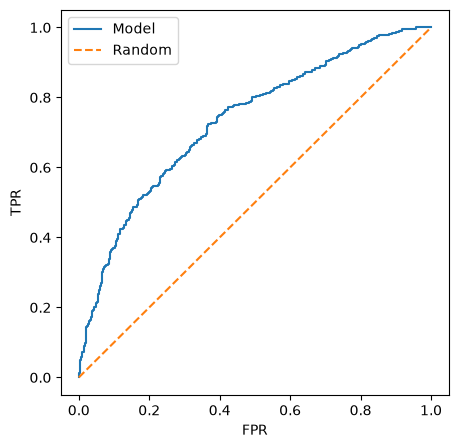

In [84]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()

### Question 3: Precision and Recall

In [90]:
actual_positive = (y_val == 1)
actual_positive

array([False,  True,  True,  True, False,  True,  True, False,  True,
        True,  True, False, False,  True, False, False, False,  True,
       False, False, False, False,  True, False,  True, False,  True,
        True,  True,  True, False,  True, False,  True,  True,  True,
        True, False,  True,  True,  True,  True, False,  True,  True,
       False,  True,  True, False, False, False,  True, False, False,
       False, False,  True,  True,  True, False,  True, False,  True,
       False, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True, False,  True,  True,  True, False,
        True, False,  True, False,  True, False,  True,  True, False,
       False,  True,  True, False,  True, False,  True, False,  True,
        True, False,  True, False, False,  True, False,  True,  True,
       False, False,  True, False,  True,  True,  True,  True,  True,
        True,  True, False, False,  True, False, False, False,  True,
       False,  True,

In [110]:
thresholds = np.linspace(0.0, 1.0, 101)

p_list = []
r_list = []

for t in thresholds:
    predicted_positive = (y_pred >= t)
    predicted_negative = (y_pred < t)
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    tp = (predicted_positive & actual_positive).sum()
    fp = (predicted_positive & actual_negative).sum()
    fn = (predicted_negative & actual_positive).sum()
    tn = (predicted_negative & actual_negative).sum()

    precision = tp / (tp + fp)
    recall = tp / (tp + fn)

    p_list.append(precision)
    r_list.append(recall)

p_list = pd.Series(p_list).fillna(1).tolist()


C:\Users\kenji\AppData\Local\Temp\ipykernel_56888\3815408201.py:17: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp / (tp + fp)


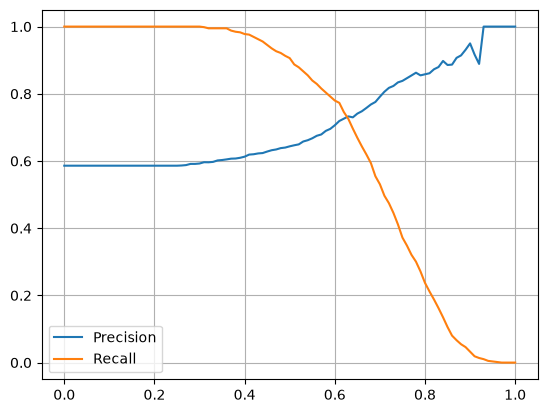

In [113]:
plt.plot(thresholds, p_list, label = 'Precision')
plt.plot(thresholds, r_list, label = 'Recall')
plt.grid()
plt.legend()

Intersection of Precision and Recall curves: threshold ~0.63

### Question 4: F1 score

threshold @ max F1:  0.41


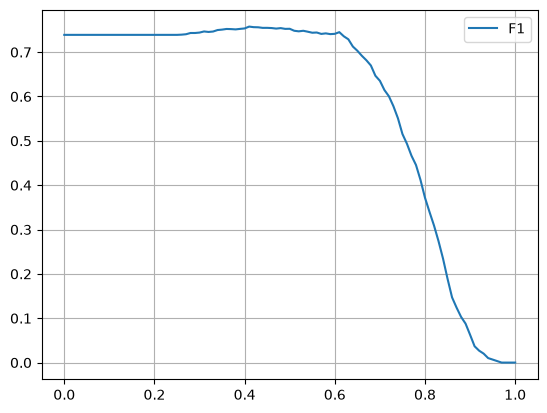

In [117]:
f1_list = []
n = 0
for t in thresholds:
    p = p_list[n]
    r = r_list[n]
    f1 = 2*p*r/(p+r)
    f1_list.append(f1)
    n= n + 1

f1_max_idx = f1_list.index(max(f1_list))
print('threshold @ max F1: ', round(thresholds[f1_max_idx],3))


plt.plot(thresholds, f1_list, label = 'F1')
plt.grid()
plt.legend()

threshold @ max F1:  0.41

### Question 5: 5-Fold CV

In [118]:
from sklearn.model_selection import KFold

In [122]:
def train(df, y_train):

    dicts = df[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model


def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:,1]

    return y_pred


In [ ]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    #print(len(y_val), len(y_pred))
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print('%.3f +- %.3f' % (np.mean(scores), np.std(scores)))

0.732 +- 0.007


standard deviation on the ROC-AUC scores of the different folds: 0.007

### Question 6: Hyperparameter Tuning

In [125]:
def train(df, y_train, C):

    dicts = df[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model


def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:,1]

    return y_pred

In [127]:
for C in [0.000001, 0.001, 1]:

    scores = []
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C)
        y_pred = predict(df_val, dv, model)

        #print(len(y_val), len(y_pred))
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007


best mean ROC-AUC achieved with C=0.001